# 02 — Tiền xử lý & Các phương án gán nhãn (Preprocessing & Labels)

## 1. Mục tiêu
Notebook này giải thích và trực quan hóa **Bước 2** trong quy trình XAI-Football:
- Lọc và chuẩn hóa chuỗi sự kiện bóng đá thành các đợt kiểm soát bóng (possessions).
- Làm sạch dữ liệu: loại bỏ đường chuyền thiếu tọa độ, thiếu người nhận, hoặc possession quá ngắn (< 2 đường chuyền).
- Phân tích phễu làm sạch (cleaning funnel).
- Phân tích chi tiết các phương án gán nhãn (possession-level vs. pass-level, shot vs. goal) phục vụ **Decision Record 0001**.
- Lưu các biểu đồ vào `results/figures/official/`.

## 2. Vị trí của bước trong pipeline
Đây là **Bước 2 — Tiền xử lý & Gán nhãn (`scripts/03_preprocess.py`, `src/xai_football/data/`)**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from xai_football.utils.output_bundle import setup_notebook_figures

# Gốc repo: chạy được cả khi kernel đứng ở notebooks/ (mặc định của Jupyter/nbconvert)
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs").is_dir())

figures_dir, bundle_figures_dir = setup_notebook_figures(step=2)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 150


## 3. Input và nguồn dữ liệu
- `results/tables/official/cleaning_report.csv`: số possession bị loại ở từng bước làm sạch.
- `results/tables/official/label_comparison.csv`: So sánh các phương án gán nhãn trên toàn bộ 380 trận đấu.
- `results/tables/official/sanity_checks.csv`: Bảng kiểm tra chất lượng dữ liệu sau làm sạch.
- `results/tables/official/data_pipeline_summary.csv`: tóm tắt số liệu toàn pipeline Bước 1-2.
- `data/interim/official/possessions.parquet`: File dữ liệu possession sau làm sạch (nếu có).

## 4. Config/script/module sử dụng
- Cấu hình: `configs/data.yaml`
- Script: `scripts/03_preprocess.py`
- Module: `src/xai_football/data/canonicalize.py`, `possession.py`, `clean.py`, `labeling.py`, `validation.py`.

## 5. Các bước xử lý & Kiểm tra dữ liệu đầu vào

In [2]:
clean_path = REPO_ROOT / "results" / "tables" / "official" / "cleaning_report.csv"
pipe_path = REPO_ROOT / "results" / "tables" / "official" / "data_pipeline_summary.csv"
label_path = REPO_ROOT / "results" / "tables" / "official" / "label_comparison.csv"
checks_path = REPO_ROOT / "results" / "tables" / "official" / "sanity_checks.csv"

for p in [clean_path, label_path]:
    if not p.exists():
        raise FileNotFoundError(f"Thiếu file: {p}. Vui lòng chạy: python scripts/03_preprocess.py --config configs/data.yaml")

df_clean = pd.read_csv(clean_path)
df_pipe = pd.read_csv(pipe_path) if pipe_path.exists() else pd.DataFrame()
df_label = pd.read_csv(label_path)
df_checks = pd.read_csv(checks_path) if checks_path.exists() else pd.DataFrame()

print("=== BÁO CÁO LÀM SẠCH (cleaning_report.csv) ===")
display(df_clean)
print("\n=== SO SÁNH CÁC PHƯƠNG ÁN GÁN NHÃN (label_comparison.csv) ===")
display(df_label)

=== BÁO CÁO LÀM SẠCH (cleaning_report.csv) ===


,possessions_input,dropped_extra_time,dropped_missing_coords,dropped_too_short,dropped_no_players,possessions_output,shot_possessions_input,shot_dropped_extra_time,shot_dropped_missing_coords,shot_dropped_too_short,shot_dropped_no_players,shot_possessions_output,shot_retention_rate
0,71884,0,0,26519,0,45365,8947,0,0,2476,0,6471,0.7233



=== SO SÁNH CÁC PHƯƠNG ÁN GÁN NHÃN (label_comparison.csv) ===


,mode,target,shot_window_seconds,n_units,n_positive,positive_rate,positive_rate_pct
0,possession_level,shot,NaN,45365,6471,0.1426,14.26
1,possession_level,goal,NaN,45365,662,0.0146,1.46
2,pass_level,shot,5.0,261205,8627,0.0330,3.30
3,pass_level,shot,10.0,261205,16321,0.0625,6.25
4,pass_level,shot,15.0,261205,22594,0.0865,8.65
5,pass_level,goal,5.0,261205,960,0.0037,0.37
6,pass_level,goal,10.0,261205,1775,0.0068,0.68
7,pass_level,goal,15.0,261205,2432,0.0093,0.93


## 6. Kết quả và cách diễn giải
### 6.1. Phễu làm sạch dữ liệu (Data Cleaning Funnel)

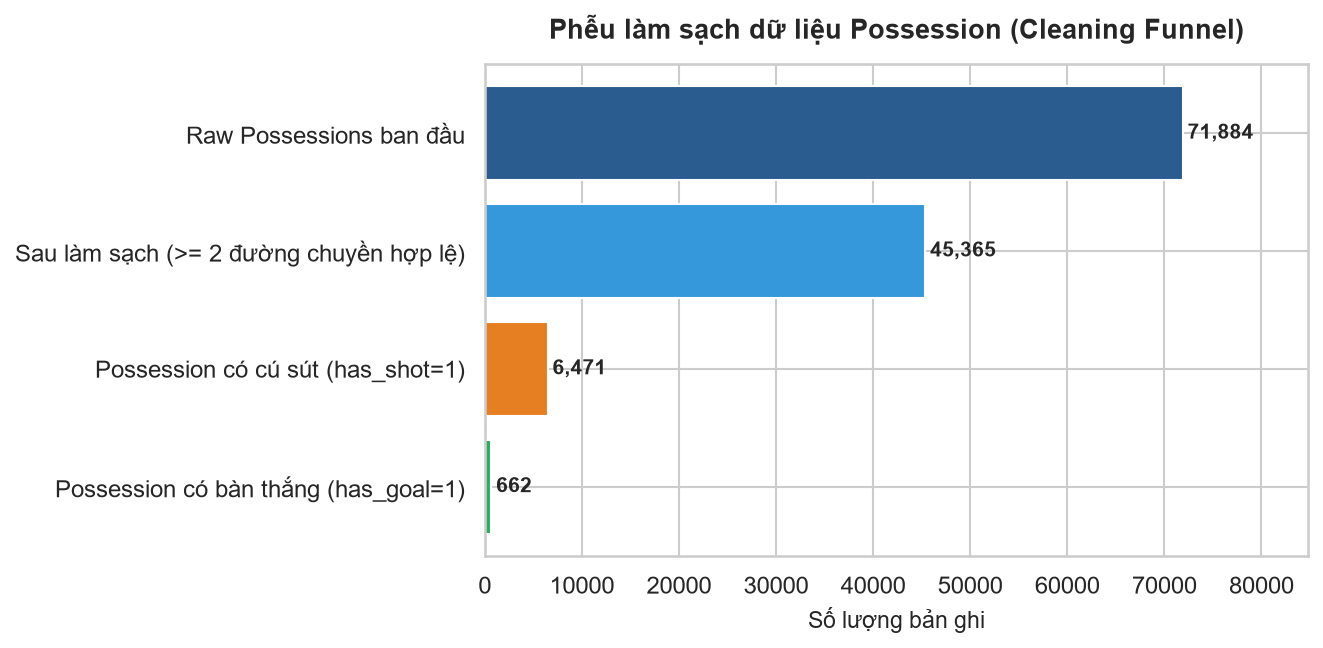

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))

steps = [
    "Raw Possessions ban đầu",
    "Sau làm sạch (>= 2 đường chuyền hợp lệ)",
    "Possession có cú sút (has_shot=1)",
    "Possession có bàn thắng (has_goal=1)",
]

# Đọc số lượng goal trực tiếp từ df_label (label_comparison.csv) hoặc df_pipe (data_pipeline_summary.csv)
goal_row = df_label[(df_label["mode"] == "possession_level") & (df_label["target"] == "goal")]
if not goal_row.empty:
    goal_count = int(goal_row["n_positive"].iloc[0])
elif not df_pipe.empty and "goal_positive_count" in df_pipe.columns:
    goal_count = int(df_pipe["goal_positive_count"].iloc[0])
else:
    raise ValueError(
        "Không tìm thấy số liệu possession có bàn thắng trong label_comparison.csv "
        "hoặc data_pipeline_summary.csv. Vui lòng chạy scripts/03_preprocess.py."
    )

counts = [
    int(df_clean["possessions_input"].iloc[0]),
    int(df_clean["possessions_output"].iloc[0]),
    int(df_clean["shot_possessions_output"].iloc[0]),
    goal_count,
]
colors = ["#2b5c8f", "#3498db", "#e67e22", "#27ae60"]

bars = ax.barh(steps, counts, color=colors)
ax.set_title("Phễu làm sạch dữ liệu Possession (Cleaning Funnel)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Số lượng bản ghi", fontsize=11)
ax.invert_yaxis()

for bar in bars:
    w = bar.get_width()
    ax.text(w + 500, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", ha="left", va="center", fontweight="bold", fontsize=10)

ax.set_xlim(0, max(counts) * 1.18)
plt.tight_layout()
plt.savefig(figures_dir / "02_cleaning_funnel.png", dpi=300)
if bundle_figures_dir.exists():
    plt.savefig(bundle_figures_dir / "02_cleaning_funnel.png", dpi=300)
plt.savefig(figures_dir / "02_cleaning_funnel.svg")
if bundle_figures_dir.exists():
    plt.savefig(bundle_figures_dir / "02_cleaning_funnel.svg")
plt.show()

### 6.2. So sánh tỉ lệ nhãn dương giữa các phương án gán nhãn (Decision Record 0001)

Số liệu cụ thể của từng phương án được tính trực tiếp từ `label_comparison.csv` (bảng ở mục 5 và
biểu đồ bên dưới), không ghi cứng trong notebook. Đọc theo: possession-level/shot cho tỉ lệ lớp dương
vừa phải; possession-level/goal rất hiếm (mất cân bằng cực đoan); pass-level phụ thuộc cửa sổ thời gian.

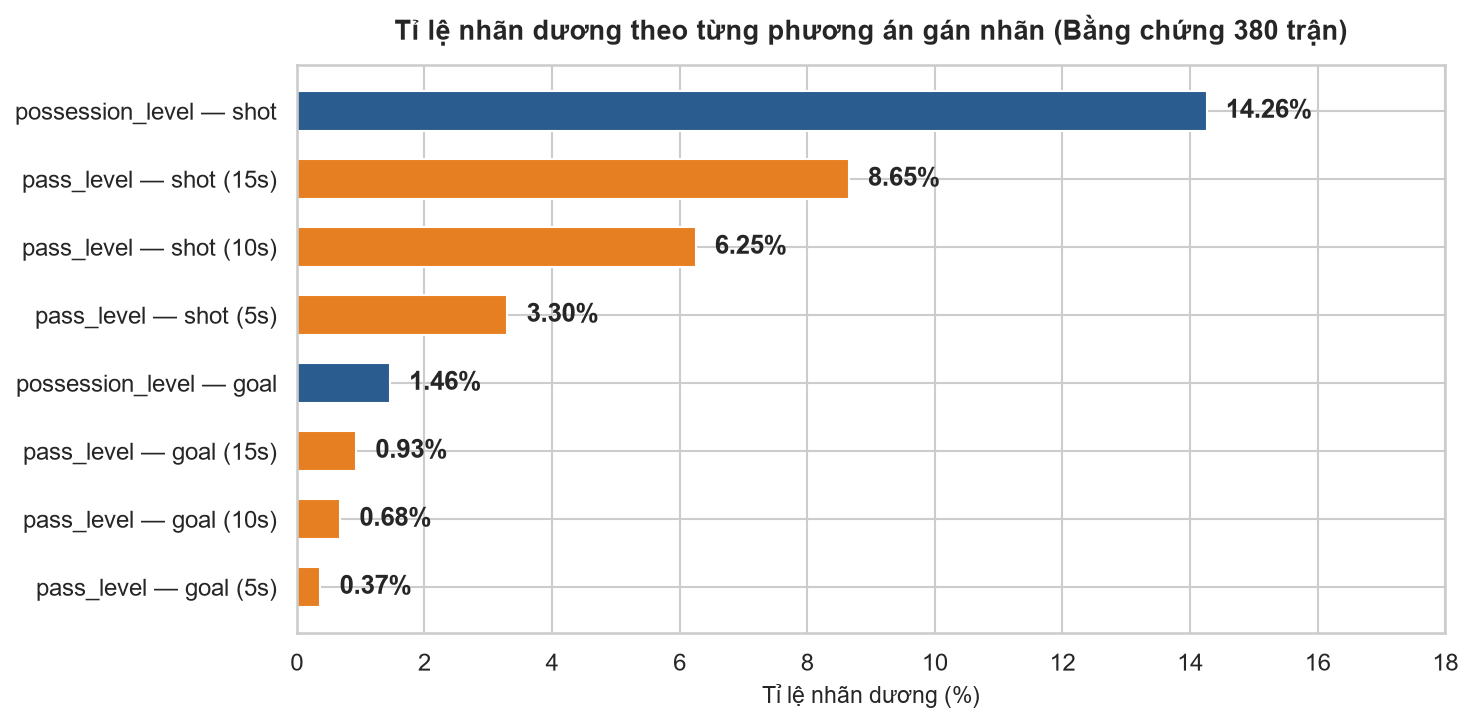

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

# Tạo tên phương án từ mode, target và window
def make_scheme_name(row):
    w = f" ({int(row['shot_window_seconds'])}s)" if pd.notna(row.get("shot_window_seconds")) else ""
    return f"{row['mode']} — {row['target']}{w}"

df_label_sorted = df_label.copy()
df_label_sorted["scheme"] = df_label_sorted.apply(make_scheme_name, axis=1)
df_label_sorted = df_label_sorted.sort_values("positive_rate_pct", ascending=True)

colors = ["#2b5c8f" if "possession" in m.lower() else "#e67e22" for m in df_label_sorted["mode"]]
bars = ax.barh(df_label_sorted["scheme"], df_label_sorted["positive_rate_pct"], color=colors, height=0.6)

ax.set_title("Tỉ lệ nhãn dương theo từng phương án gán nhãn (Bằng chứng 380 trận)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Tỉ lệ nhãn dương (%)", fontsize=11)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height() / 2, f"{w:.2f}%", ha="left", va="center", fontweight="bold")

ax.set_xlim(0, 18)
plt.tight_layout()
plt.savefig(figures_dir / "02_label_comparison.png", dpi=300)
if bundle_figures_dir.exists():
    plt.savefig(bundle_figures_dir / "02_label_comparison.png", dpi=300)
plt.savefig(figures_dir / "02_label_comparison.svg")
if bundle_figures_dir.exists():
    plt.savefig(bundle_figures_dir / "02_label_comparison.svg")
plt.show()

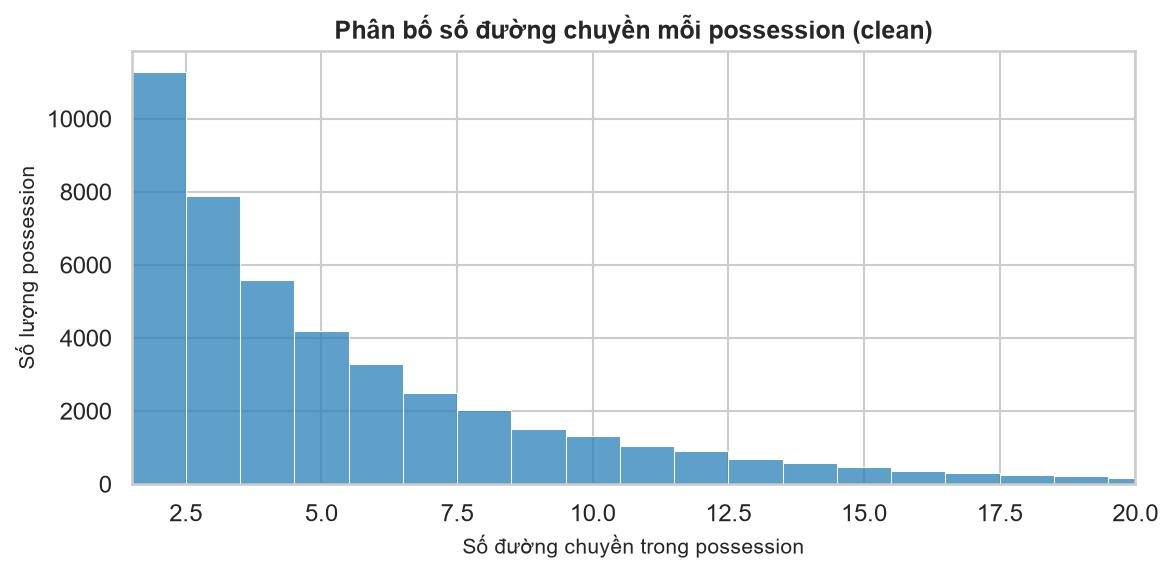

In [5]:
# Nếu có file possessions.parquet, trực quan hóa phân bố độ dài possession
poss_path = REPO_ROOT / "data" / "interim" / "official" / "possessions.parquet"
if poss_path.exists():
    df_poss = pd.read_parquet(poss_path)
    if "n_passes" in df_poss.columns:
        fig, ax = plt.subplots(figsize=(8, 4))
        sns.histplot(df_poss["n_passes"], bins=range(2, 25), discrete=True, color="#2980b9", ax=ax)
        ax.set_title("Phân bố số đường chuyền mỗi possession (clean)", fontsize=12, fontweight="bold")
        ax.set_xlabel("Số đường chuyền trong possession", fontsize=10)
        ax.set_ylabel("Số lượng possession", fontsize=10)
        ax.set_xlim(1.5, 20)
        plt.tight_layout()
        plt.savefig(figures_dir / "02_possession_length_dist.png", dpi=300)
        if bundle_figures_dir.exists():
            plt.savefig(bundle_figures_dir / "02_possession_length_dist.png", dpi=300)
        plt.savefig(figures_dir / "02_possession_length_dist.svg")
        if bundle_figures_dir.exists():
            plt.savefig(bundle_figures_dir / "02_possession_length_dist.svg")
        plt.show()

## 7. Kiểm tra chất lượng (Quality Checks)

In [6]:
if not df_checks.empty:
    print("=== BẢNG KIỂM TRA CHẤT LƯỢNG LÀM SẠCH ===")
    display(df_checks)
    critical_fails = df_checks[df_checks["status"] == "FAIL"]
    assert len(critical_fails) == 0, f"Có {len(critical_fails)} kiểm tra bị FAIL!"
    print("Toàn bộ các phép kiểm tra làm sạch đều đạt chuẩn PASS.")

=== BẢNG KIỂM TRA CHẤT LƯỢNG LÀM SẠCH ===


,check,value,status,note
0,match_count == 380,380,PASS,NaN
1,"unique_teams in [18, 24]",20,PASS,NaN
2,"median_events_per_match in [1000, 4500]",3454.0,PASS,"min=2670, max=4264"
3,"median_possessions_per_match in [90, 130]",119.0,PASS,"min=90, max=162"
4,"median_successful_passes_per_match in [500, 1200]",683.5,PASS,"min=340, max=1002"
5,missing_coordinate_rate < 0.05,0.0061,PASS,8077/1313773 events thiếu tọa độ
6,successful_pass_coordinate_missingness < 0.01,0.0,PASS,"start_missing=0, end_missing=0 / 261205 passes"
7,missing_recipient_rate < 0.15,0.0768,PASS,28294/368619 passes thiếu recipient
8,no_duplicate_possession_keys,0,PASS,NaN
9,no_opponent_passes_in_possession,0,PASS,NaN


Toàn bộ các phép kiểm tra làm sạch đều đạt chuẩn PASS.


## 8. Output được lưu ở đâu
- Bảng kết quả: `results/tables/official/cleaning_report.csv`, `label_comparison.csv`, `sanity_checks.csv`, `play_pattern_distribution.csv`, `data_pipeline_summary.csv`.
- Dữ liệu trung gian: `data/interim/official/possessions.parquet`, `possession_events.parquet`, `events.parquet`.
- Biểu đồ:
  - `results/figures/official/02_cleaning_funnel.png` (và `.svg`)
  - `results/figures/official/02_label_comparison.png` (và `.svg`)
  - `results/figures/official/02_possession_length_dist.png` (và `.svg`)

## 9. Cách tái chạy
```bash
python scripts/03_preprocess.py --config configs/data.yaml
```

## 10. Giới hạn và giả định
- **Decision Record 0001 vẫn ở trạng thái `Chưa quyết định`**: Hiện tại pipeline tạm thời áp dụng nhãn `possession_level` (mục tiêu `shot`).
- Khái niệm `has_shot` (possession chứa ít nhất 1 cú sút) được phân biệt rõ với `ends_with_shot` (possession kết thúc bằng cú sút).